In [1]:
import os
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)


In [4]:
conn = sqlite3.connect(':memory:')

raw_df = pd.read_csv(r'C:\Users\Acer\OneDrive\Desktop\Дата-аналитика\пэт проекты\education-grants-analytics\data\students_data.csv', sep=None, engine='python')
# Убираем пробелы и круглые скобки из названий столбцов
raw_df.columns = [
    c.strip().replace('(', '').replace(')', '').replace(' ', '_').replace('\t', '') 
    for c in raw_df.columns
]
raw_df.to_sql('students_data', conn, index=False)

sql_query = """
WITH student_base AS (
    SELECT 
        ROW_NUMBER() OVER() AS student_id,
        Course AS course,
        Gender AS gender,
        Age_at_enrollment AS age,
        Scholarship_holder AS scholarship_holder,
        Tuition_fees_up_to_date AS fees_up_to_date,
        Previous_qualification_grade AS school_grade,
        Admission_grade AS admission_grade,
        Curricular_units_1st_sem_enrolled AS units_1st_enrolled,
        Curricular_units_1st_sem_approved AS units_1st_approved,
        Curricular_units_1st_sem_grade AS grade_1st_sem,
        Curricular_units_2nd_sem_grade AS grade_2nd_sem,
        Target AS target
    FROM students_data
    WHERE Admission_grade > 0
)
SELECT 
    *,
    ROUND(CAST(units_1st_approved AS REAL) / NULLIF(units_1st_enrolled, 0) * 100, 2) AS pass_rate_1st_sem,
    ROUND(AVG(grade_2nd_sem) OVER(PARTITION BY course), 2) AS avg_course_grade
FROM student_base;
"""

df = pd.read_sql_query(sql_query, conn)
print(f"Выгружено записей из SQL: {len(df)}")


Выгружено записей из SQL: 4424


In [5]:
# Проверяем структуру, типы данных и наличие пропусков до очистки
print("=== Структура и типы данных ===")
print(df.info())
print("\n=== Количество пропусков по столбцам ===")
print(df.isna().sum())

initial_rows = len(df)
df = df.drop_duplicates(subset=['student_id'])

# Оставляем студентов, дошедших до аттестации в 1-м и 2-м семестрах (исключаем нулевые оценки)
df_clean = df[(df['grade_1st_sem'] > 0) & (df['grade_2nd_sem'] > 0)].copy()

df_clean['is_dropout'] = (df_clean['target'] == 'Dropout').astype(int)
df_clean['is_graduate'] = (df_clean['target'] == 'Graduate').astype(int)
df_clean['grant_status'] = df_clean['scholarship_holder'].map({1: 'С грантом', 0: 'Без гранта'})

print(f"\nБыло строк: {initial_rows} | Стало: {len(df_clean)}")
print(f"Сохранено данных: {len(df_clean)/initial_rows:.1%} (исключены студенты без итоговых оценок за семестры)")


=== Структура и типы данных ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          4424 non-null   int64  
 1   course              4424 non-null   int64  
 2   gender              4424 non-null   int64  
 3   age                 4424 non-null   int64  
 4   scholarship_holder  4424 non-null   int64  
 5   fees_up_to_date     4424 non-null   int64  
 6   school_grade        4424 non-null   float64
 7   admission_grade     4424 non-null   float64
 8   units_1st_enrolled  4424 non-null   int64  
 9   units_1st_approved  4424 non-null   int64  
 10  grade_1st_sem       4424 non-null   float64
 11  grade_2nd_sem       4424 non-null   float64
 12  target              4424 non-null   object 
 13  pass_rate_1st_sem   4244 non-null   float64
 14  avg_course_grade    4424 non-null   float64
dtypes: float64(6), int64(8)

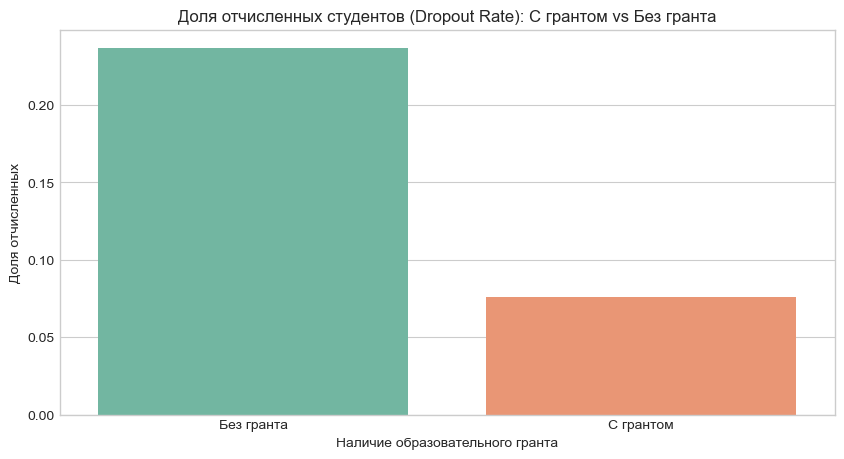

grant_status  students  dropout_rate  graduation_rate  avg_grade_2nd
  Без гранта      2509      0.236748         0.527700      12.656939
   С грантом      1003      0.075773         0.805583      12.968079


In [6]:
grant_eda = df_clean.groupby('grant_status').agg(
    students=('student_id', 'count'),
    dropout_rate=('is_dropout', 'mean'),
    graduation_rate=('is_graduate', 'mean'),
    avg_grade_2nd=('grade_2nd_sem', 'mean')
).reset_index()

sns.barplot(
    data=grant_eda,
    x='grant_status',
    y='dropout_rate',
    hue='grant_status',
    palette='Set2',
    legend=False
)
plt.title('Доля отчисленных студентов (Dropout Rate): С грантом vs Без гранта')
plt.xlabel('Наличие образовательного гранта')
plt.ylabel('Доля отчисленных')
plt.show()

print(grant_eda.to_string(index=False))


In [7]:
kpi_table = df_clean.groupby(['grant_status', 'fees_up_to_date']).agg(
    total_students=('student_id', 'count'),
    pass_rate_1sem=('pass_rate_1st_sem', 'mean'),
    avg_2nd_sem_grade=('grade_2nd_sem', 'mean'),
    graduation_rate=('is_graduate', 'mean'),
    dropout_rate=('is_dropout', 'mean')
).round(3)

print("=== Образовательные KPI по грантам и своевременности оплаты ===")
print(kpi_table)


=== Образовательные KPI по грантам и своевременности оплаты ===
                              total_students  pass_rate_1sem  \
grant_status fees_up_to_date                                   
Без гранта   0                           227          70.204   
             1                          2282          84.278   
С грантом    0                            32          85.134   
             1                           971          91.876   

                              avg_2nd_sem_grade  graduation_rate  dropout_rate  
grant_status fees_up_to_date                                                    
Без гранта   0                           12.134            0.079         0.797  
             1                           12.709            0.572         0.181  
С грантом    0                           12.109            0.250         0.469  
             1                           12.996            0.824         0.063  


In [8]:
features = ['school_grade', 'admission_grade', 'grade_1st_sem', 'pass_rate_1st_sem', 'scholarship_holder', 'age']
X = df_clean[features].fillna(0)
y = df_clean['grade_2nd_sem']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
preds = model.predict(X_test)

print(f"Точность модели R2: {r2_score(y_test, preds):.3f}")
print(f"Средняя абсолютная ошибка (MAE): {mean_absolute_error(y_test, preds):.2f} балла")
for feat, coef in zip(features, model.coef_):
    print(f"Влияние фактора '{feat}': {coef:+.3f}")


Точность модели R2: 0.450
Средняя абсолютная ошибка (MAE): 0.79 балла
Влияние фактора 'school_grade': +0.004
Влияние фактора 'admission_grade': +0.005
Влияние фактора 'grade_1st_sem': +0.619
Влияние фактора 'pass_rate_1st_sem': +0.011
Влияние фактора 'scholarship_holder': +0.034
Влияние фактора 'age': +0.002


In [10]:
grant_grades = df_clean[df_clean['scholarship_holder'] == 1]['grade_2nd_sem']
no_grant_grades = df_clean[df_clean['scholarship_holder'] == 0]['grade_2nd_sem']

stat, p_val = stats.mannwhitneyu(grant_grades, no_grant_grades, alternative='greater')
print(f"Медианный балл (С грантом): {grant_grades.median():.2f}")
print(f"Медианный балл (Без гранта): {no_grant_grades.median():.2f}")
print(f"p-value: {p_val:.6f}")

if p_val < 0.05:
    print("ВЫВОД: Различие статистически значимо (отвергаем нулевую гипотезу).")
else:
    print("ВЫВОД: Различие случайно.")

os.makedirs(r'C:\Users\Acer\OneDrive\Desktop\Дата-аналитика\пэт проекты\education-grants-analytics\data', exist_ok=True)
df_clean.to_csv(r'C:\Users\Acer\OneDrive\Desktop\Дата-аналитика\пэт проекты\education-grants-analytics\data\education_powerbi_clean.csv', index=False, sep=';', encoding='utf-8-sig')
print("\nФайл education_powerbi_clean.csv успешно сохранен в папку data/!")


Медианный балл (С грантом): 12.86
Медианный балл (Без гранта): 12.55
p-value: 0.000000
ВЫВОД: Различие статистически значимо (отвергаем нулевую гипотезу).

Файл education_powerbi_clean.csv успешно сохранен в папку data/!


In [ ]:
with open('extract_education.sql', 'w', encoding='utf-8') as f:
    f.write(sql_query.strip())

req_text = """pandas==2.2.2
seaborn==0.13.2
matplotlib==3.8.4
scipy==1.13.0
scikit-learn==1.4.2"""
with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write(req_text)

gitignore_text = """.ipynb_checkpoints/
__pycache__/
*.csv
*.xlsx
data/
.env"""
with open('.gitignore', 'w', encoding='utf-8') as f:
    f.write(gitignore_text)

print("Файлы extract_education.sql, requirements.txt и .gitignore созданы!")
